# Spallation test
Analyze `spallation_test.bin` from `transport_spallation_loss.cpp`. Run this notebook from the simulation directory.

Each record contains five native-endian float64 values: x, y, z [pc], total energy per nucleon E [GeV/n], and final species ID. IDs are 0=O16, 1=N15, 2=N14, 3=C13, 4=C12, 5=B11, 6=B10, 7=Be10, 8=Be9, 9=Be7; -1 denotes destruction into untracked fragments. Every initial particle is retained in its original order.

The notebook analyzes final abundances, energy losses, B/C, and spatial transport. The source is uniform in a cylinder (R=10 kpc, z=±100 pc in the current C++ source); the wind is u_z=a z with a=1e-8 yr^-1, and adiabatic losses cool the particles. Gas density is constant at 0.1 cm^-3. Records retain their initial order, so the injected log-energy grid can be reconstructed, but propagation times, initial species, and initial positions are not saved. Run parameters and `cross_section.hpp` must match the binary.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re
from scipy.linalg import expm
from matplotlib.colors import LogNorm

plt.rcParams.update({'figure.dpi': 120, 'axes.grid': False})

In [11]:
# Parameters in the current transport_spallation_loss.cpp; the binary has no run metadata.
# Change these if the file was generated with different parameters.
file = Path("spallation_test.bin")
N = 21000
E_min = 10.0       # total energy per nucleon, GeV/n
E_max = 1e6
nH = 0.1          # cm^-3; constant in this run
t_end = 1e8        # yr
a_wind = 1e-8     # yr^-1; u_z = a_wind * z and div(u) = a_wind
m_p = 0.938272    # GeV/c^2 per nucleon for the adiabatic energy update
source_radius_pc = 1.0e4
source_half_height_pc = 100.0  # current C++ value; total thickness 200 pc
c = 2.99792458e10  # cm / s
c_pc = 0.30660139  # pc / yr
yr2s = 31557600.0

if file.stat().st_size == 0 or file.stat().st_size % 40:
    raise ValueError("Expected nonempty records of five float64 values (40 bytes); regenerate legacy output")
data = np.fromfile(file, dtype="=f8").reshape(-1, 5)
x, y, z, E, species_raw = data.T
xyz = data[:, :3]
n = len(E)
assert np.isfinite(data).all() and np.all(E > 0)
assert n == N, "Particle count does not match the run parameters"

print("Number of records:", n)
print("E min / median / max [GeV/n]:", np.percentile(E, [0, 50, 100]))
print("Mean position [pc]:", xyz.mean(axis=0))
print("Coordinate standard deviations [pc]:", xyz.std(axis=0, ddof=1))
if not np.all(np.isin(species_raw, np.arange(-1, 10))):
    raise ValueError("Species IDs must be integers from -1 to 9")
species = species_raw.astype(int)
tracked = species >= 0
destroyed = ~tracked
Ei = np.logspace(np.log10(E_min), np.log10(E_max), n)  # initial energy from record order
p_initial = np.sqrt(Ei**2 - m_p**2)
p_final = np.sqrt(np.maximum(E**2 - m_p**2, 0.0))
elapsed_inferred = -3.0 / a_wind * np.log(p_final / p_initial)
if np.any(elapsed_inferred < -1e-5) or np.any(elapsed_inferred > t_end + 1e3):
    raise ValueError("Final energies are inconsistent with the assumed adiabatic-only cooling history")
elapsed_inferred = np.clip(elapsed_inferred, 0.0, t_end)
print("Inferred elapsed time min / median / max [yr]:", np.percentile(elapsed_inferred, [0, 50, 100]))
print("Tracked / destroyed:", tracked.sum(), destroyed.sum())


Number of records: 21000
E min / median / max [GeV/n]: [7.20297129e+00 2.60901346e+03 9.89776428e+05]
Mean position [pc]: [ -7.19116268 251.31670865 -40.23144486]
Coordinate standard deviations [pc]: [24388.52963466 24956.54235616 38347.54431816]
Inferred elapsed time min / median / max [yr]: [1.06186400e+02 5.73746791e+07 1.00000000e+08]
Tracked / destroyed: 6129 14871


## Injected and final energy spectra
The initial energy is a deterministic logarithmic grid in record order. Final energies are lower because of adiabatic cooling; spallation preserves energy per nucleon in the straight-ahead approximation. Elapsed time is inferred from the initial/final momentum ratio, assuming the configured constant divergence.

Initial E min / median / max [GeV/n]: [1.00000000e+01 3.16227778e+03 1.00000000e+06]
Final E min / median / max [GeV/n]: [7.20297129e+00 2.60901346e+03 9.89776428e+05]


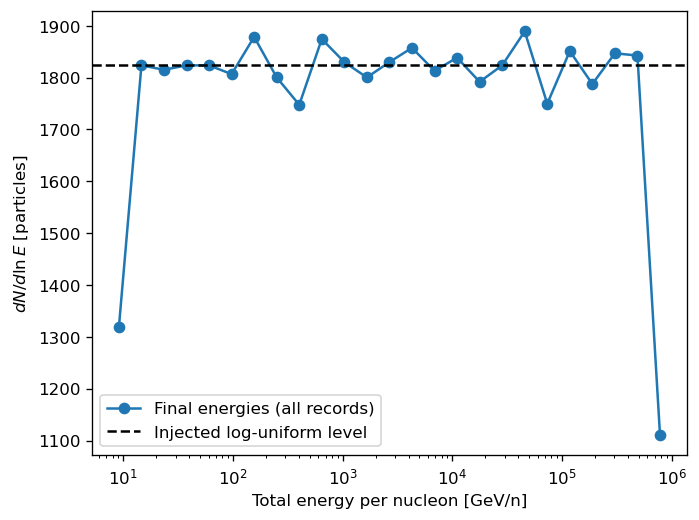

In [14]:
print("Initial E min / median / max [GeV/n]:", np.percentile(Ei, [0, 50, 100]))
print("Final E min / median / max [GeV/n]:", np.percentile(E, [0, 50, 100]))

bins = np.geomspace(E.min() * (1 - 1e-12), E.max() * (1 + 1e-12), 26)
counts, _ = np.histogram(E, bins=bins)
dE = np.diff(bins)
dlnE = np.diff(np.log(bins))
Ec = np.sqrt(bins[:-1] * bins[1:])
assert counts.sum() == n

plt.plot(Ec, counts / dlnE, "o-", label="Final energies (all records)")
plt.axhline(n / np.log(E_max / E_min), linestyle="--", color="black",
            label="Injected log-uniform level")
plt.xscale("log")
plt.xlabel("Total energy per nucleon [GeV/n]")
plt.ylabel(r"$dN/d\ln E$ [particles]")
plt.legend()
plt.show()

## Fragmentation network prediction
Read the isotope order and cross-section matrix from `cross_section.hpp`. For a row vector of populations, the generator has off-diagonal entries nH c sigma(i → j), diagonal entries −nH c sigma(inelastic), and one absorbing state for untracked fragments. The matrix exponential includes sequential fragmentation chains and predicts the measured endpoint abundances for the constant-density, v ≈ c model. It does not add radioactive decay or helium targets.


In [15]:
header = Path("cross_section.hpp").read_text()
nuclide_block = header.split("nuclides", 1)[1].split("constexpr std::size_t index", 1)[0]
names = re.findall(r'\{\s*"([A-Za-z0-9]+)"\s*,', nuclide_block)
sigma_block = header.split("sigma{", 1)[1].split(";", 1)[0]
values = re.findall(r'(?<![\w.])[+-]?(?:\d+\.\d*|\d*\.\d+|\d+)(?:[eE][+-]?\d+)?', sigma_block)
k = len(names)
sigma = np.array(values, dtype=float).reshape(k, k)  # cm^2
assert k == 10
partial = sigma.copy()
np.fill_diagonal(partial, 0)
missing = np.diag(sigma) - partial.sum(axis=1)
assert np.all(partial >= 0) and np.all(missing >= 0)

rate = nH * c * yr2s
Q = np.zeros((k + 1, k + 1))
Q[:k, :k] = rate * partial
Q[np.arange(k), np.arange(k)] = -rate * np.diag(sigma)
Q[:k, k] = rate * missing
assert np.allclose(Q.sum(axis=1), 0, atol=1e-20)

initial = np.zeros(k + 1)
initial[names.index("O16")] = n * 10 / 21
initial[names.index("N14")] = n / 21
initial[names.index("C12")] = n * 10 / 21
pred = initial @ expm(Q * t_end)
assert np.all(pred >= -1e-8) and np.isclose(pred.sum(), n)

print("species       initial       predicted final")
for name, a, b in zip(names + ["untracked"], initial, pred):
    print(f"{name:>9} {a:13.0f} {b:21.6g}")
print("Predicted tracked fraction:", pred[:k].sum() / n)
C = pred[names.index("C12")] + pred[names.index("C13")]
B = pred[names.index("B10")] + pred[names.index("B11")]
print("Predicted B/C:", B / C if C > 0 else np.nan)

species       initial       predicted final
      O16         10000                624.19
      N15             0               382.789
      N14          1000               322.383
      C13             0               277.746
      C12         10000               1594.64
      B11             0               1173.49
      B10             0               662.955
     Be10             0               196.538
      Be9             0               352.246
      Be7             0               549.396
untracked             0               14863.6
Predicted tracked fraction: 0.29220790757423837
Predicted B/C: 0.980804367879422


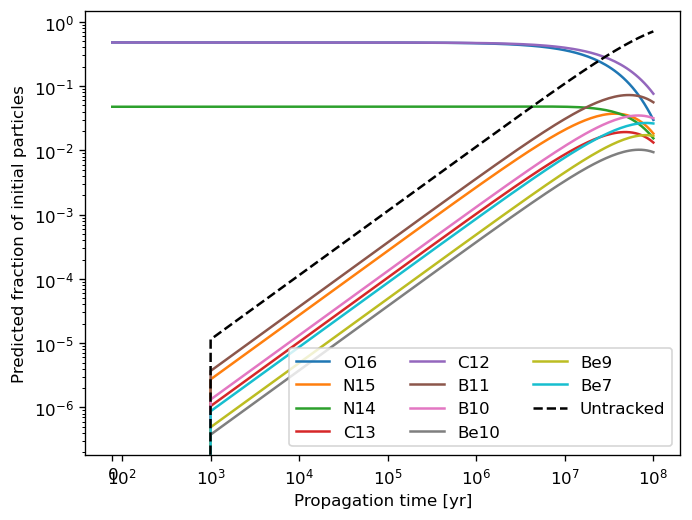

In [16]:
times = np.r_[0, np.geomspace(1e3, t_end, 150)]
pop = np.array([initial @ expm(Q * t) for t in times])
for j, name in enumerate(names):
    plt.plot(times, pop[:, j] / n, label=name)
plt.plot(times, pop[:, -1] / n, "k--", label="Untracked")
plt.xscale("symlog", linthresh=1e3)
plt.yscale("log")
plt.xlabel("Propagation time [yr]")
plt.ylabel("Predicted fraction of initial particles")
plt.legend(ncol=3)
plt.show()

## Measured endpoint abundances and spectra
Compare all ten tracked isotopes and the untracked category with the network expectation. Error bars show marginal counting standard deviations. Energy-bin expectations use the injected mixture averaged over the random species shuffle; the exact initial species in each bin are unavailable.


species       measured       predicted
      O16            621         624.190
      N15            397         382.789
      N14            337         322.383
      C13            276         277.746
      C12           1632        1594.637
      B11           1143        1173.487
      B10            666         662.955
     Be10            194         196.538
      Be9            345         352.246
      Be7            518         549.396
Untracked          14871       14863.634
Measured tracked fraction: 0.29185714285714287


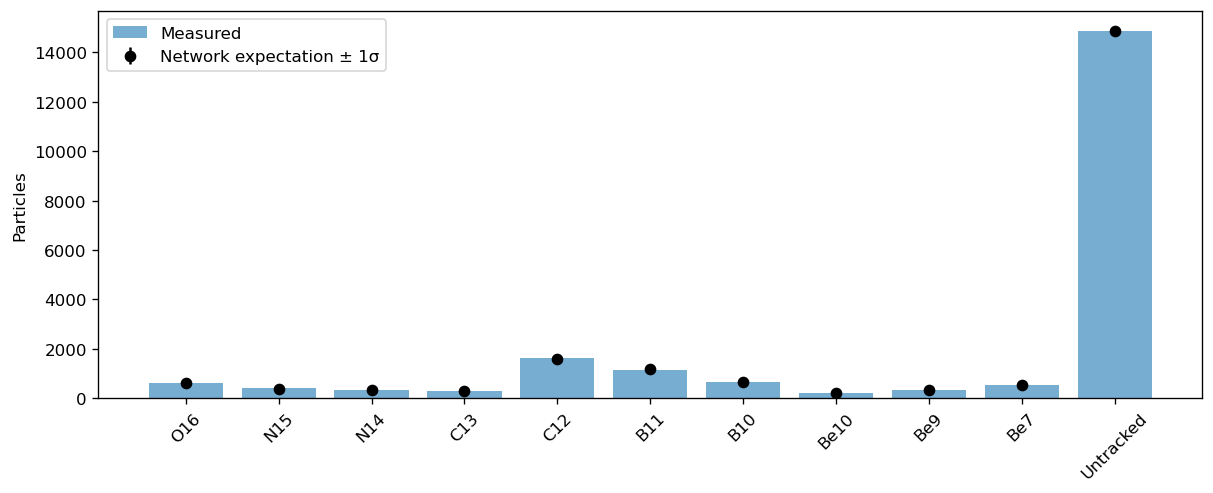

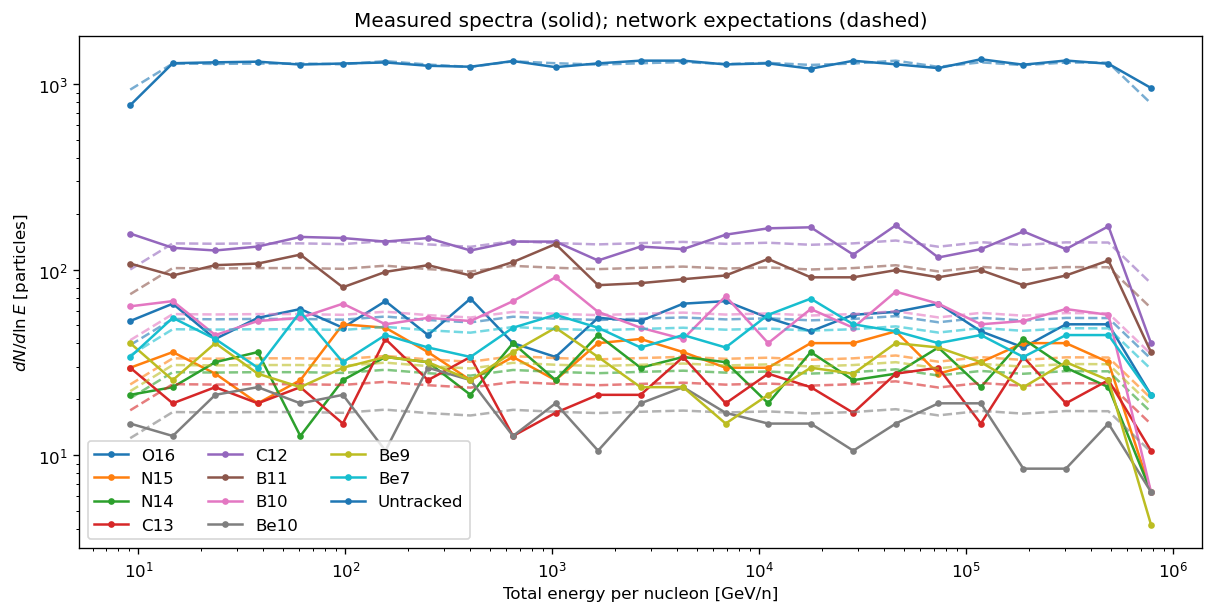

In [17]:
labels = names + ["Untracked"]
# Map -1 to the absorbing category, preserving the header's isotope ordering.
category = np.where(tracked, species, k)
observed = np.bincount(category, minlength=k + 1)
assert observed.sum() == n
probability = pred / n
abundance_error = np.sqrt(n * probability * (1 - probability))
print("species       measured       predicted")
for name, count, expected_count in zip(labels, observed, pred):
    print(f"{name:>9} {count:14d} {expected_count:15.3f}")
print("Measured tracked fraction:", tracked.mean())

fig, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
positions = np.arange(k + 1)
ax.bar(positions, observed, alpha=0.6, label="Measured")
ax.errorbar(positions, pred, yerr=abundance_error, fmt="ko", label="Network expectation ± 1σ")
ax.set_xticks(positions, labels, rotation=45)
ax.set_ylabel("Particles")
ax.legend()
plt.show()

spectra = np.array([np.histogram(E[category == j], bins=bins)[0] for j in range(k + 1)])
assert np.array_equal(spectra.sum(axis=0), counts)
fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
for j, name in enumerate(labels):
    line, = ax.plot(Ec, spectra[j] / dlnE, "o-", markersize=3, label=name)
    ax.plot(Ec, counts * probability[j] / dlnE, "--", color=line.get_color(), alpha=0.6)
ax.set(xscale="log", yscale="log", xlabel="Total energy per nucleon [GeV/n]",
       ylabel=r"$dN/d\ln E$ [particles]", title="Measured spectra (solid); network expectations (dashed)")
ax.legend(ncol=3)
plt.show()


Measured B / C counts: 1809 1908
Measured integrated B/C: 0.9481132075471698
Predicted integrated B/C: 0.980804367879422


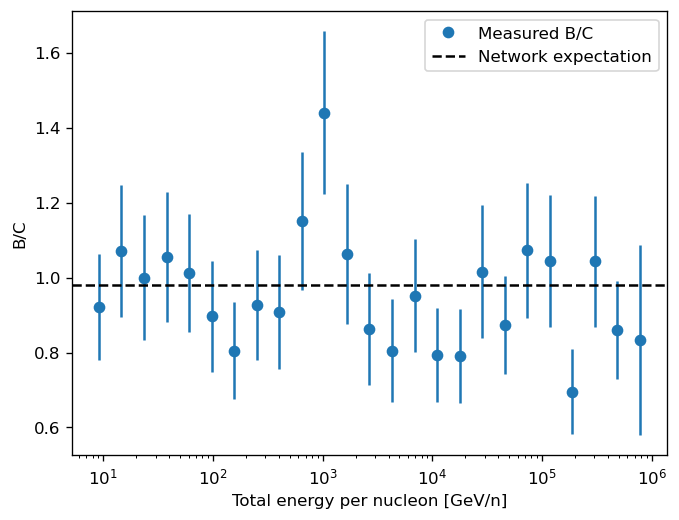

Bins with zero carbon (undefined B/C): 0
Ratio uncertainties use a large-count approximation; sparse bins need caution.


In [18]:
B_counts = spectra[[names.index("B10"), names.index("B11")]].sum(axis=0)
C_counts = spectra[[names.index("C12"), names.index("C13")]].sum(axis=0)
measured_B = observed[names.index("B10")] + observed[names.index("B11")]
measured_C = observed[names.index("C12")] + observed[names.index("C13")]
print("Measured B / C counts:", measured_B, measured_C)
print("Measured integrated B/C:", measured_B / measured_C if measured_C else np.nan)
print("Predicted integrated B/C:", B / C if C else np.nan)

ratio = np.full(len(Ec), np.nan)
np.divide(B_counts, C_counts, out=ratio, where=C_counts > 0)
# Large-count approximation; omit uncertainty bars when either count is zero.
valid = (B_counts > 0) & (C_counts > 0)
ratio_error = ratio[valid] * np.sqrt(1 / B_counts[valid] + 1 / C_counts[valid])
plt.plot(Ec, ratio, "o", label="Measured B/C")
plt.errorbar(Ec[valid], ratio[valid], yerr=ratio_error, fmt="none", color="C0")
plt.axhline(B / C if C else np.nan, color="black", linestyle="--", label="Network expectation")
plt.xscale("log")
plt.xlabel("Total energy per nucleon [GeV/n]")
plt.ylabel("B/C")
plt.legend()
plt.show()
print("Bins with zero carbon (undefined B/C):", np.count_nonzero(C_counts == 0))
print("Ratio uncertainties use a large-count approximation; sparse bins need caution.")


## Final spatial distribution
The output contains final positions, not injection positions. The initial source is a uniform disk of radius 10 kpc and half-height 100 pc (matching the current C++ source). Removed particles stop at their removal time, so all records mix propagation durations. The wind is linear in z, not a constant vertical speed; it does not shift x or y.

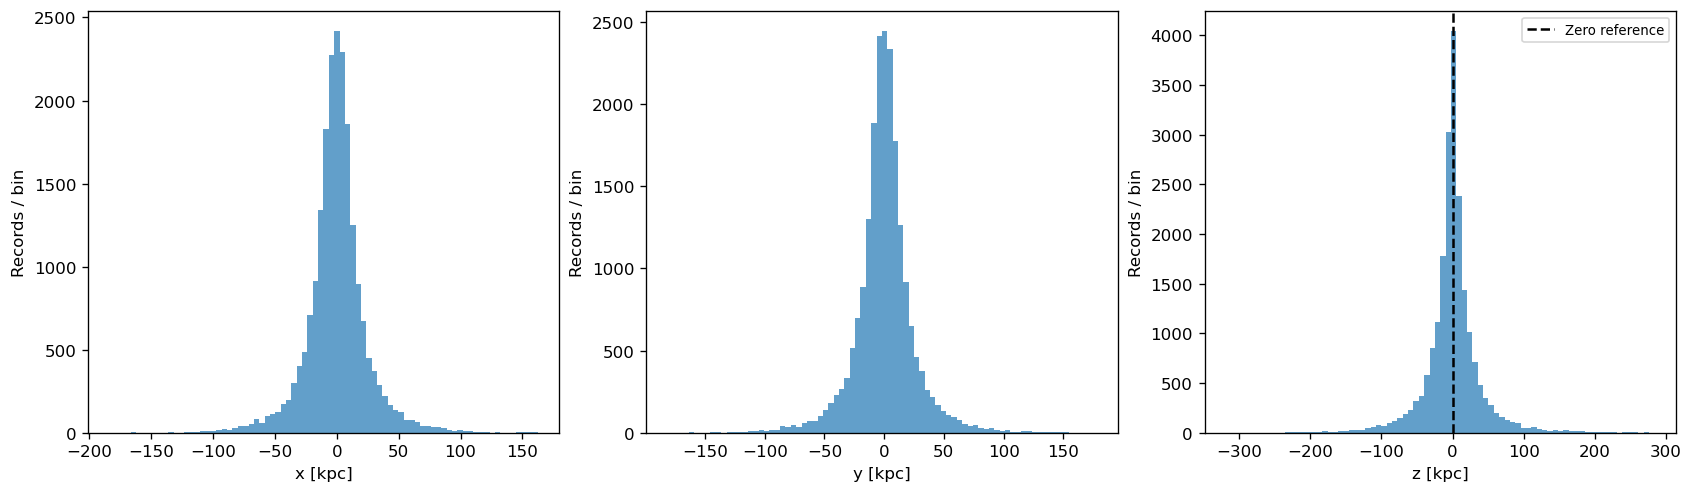

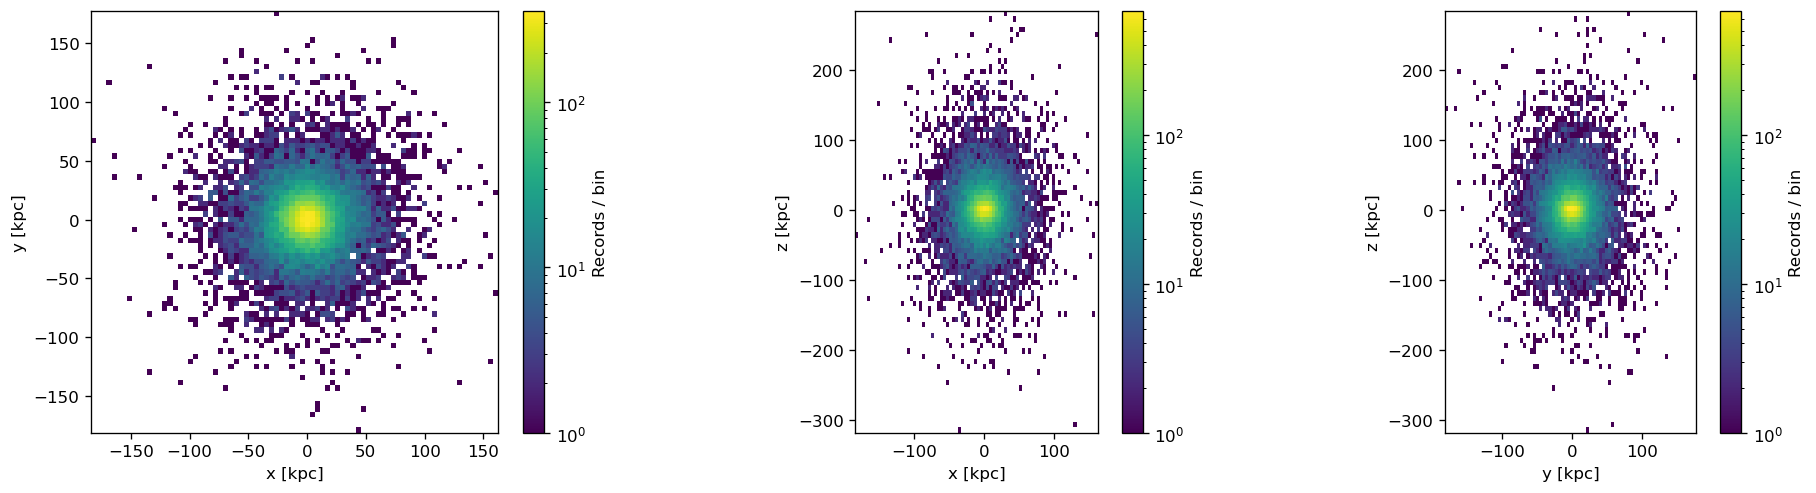

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)
for j, ax in enumerate(axes):
    ax.hist(xyz[:, j] / 1000, bins=80, alpha=0.7)
    ax.set(xlabel="xyz"[j] + " [kpc]", ylabel="Records / bin")
axes[2].axvline(0, color="black", linestyle="--", label="Zero reference")
axes[2].legend(fontsize=8)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    hist = ax.hist2d(xyz[:, i] / 1000, xyz[:, j] / 1000,
                     bins=80, norm=LogNorm(), cmin=1)
    ax.set(xlabel="xyz"[i] + " [kpc]", ylabel="xyz"[j] + " [kpc]", aspect="equal")
    fig.colorbar(hist[3], ax=ax, label="Records / bin")
plt.show()

## Mean stopping time and transverse diffusion check
For constant density and energy-independent cross sections, the fragmentation network predicts mean duration from the integral of tracked survival. Final energy gives an approximate duration under the assumed adiabatic law. In the transverse plane, the source contributes E[x0²+y0²]=R²/2 and diffusion contributes 4∫D(E(t))dt, where D=c_pc lambda/3 and lambda=2 E^(1/3). The energy-dependent prediction is integrated along each inferred cooling history.

Predicted mean propagation duration [yr]: 58223823.116991654
Mean inferred duration [yr]: 58101309.23297798
Predicted network mean duration [yr]: 58223823.116991654
Largest transport timestep [yr]: 325.04107784440936


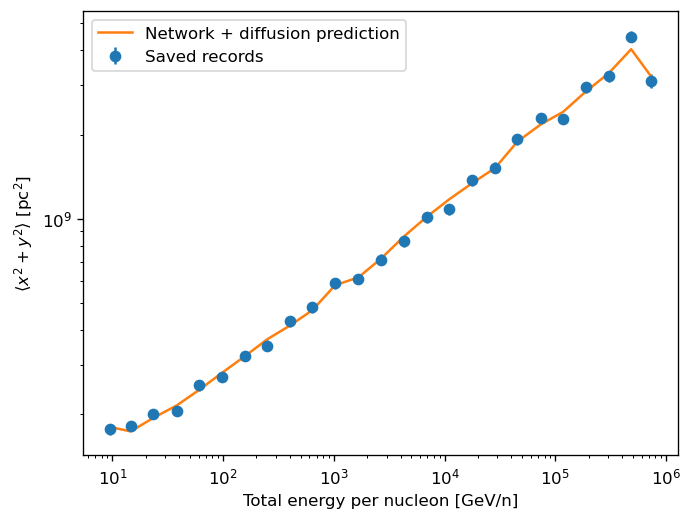

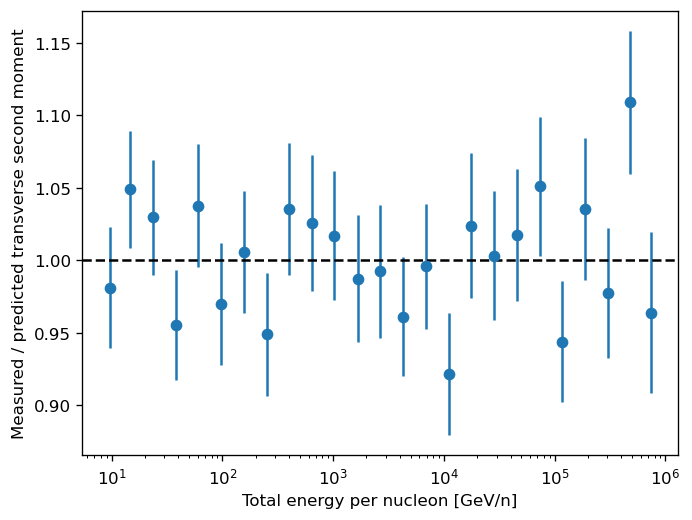

In [20]:
# Augment the generator with an accumulator for integrated tracked survival.
A = np.zeros((k + 2, k + 2))
A[:k + 1, :k + 1] = Q
A[:k, -1] = 1.0
p0 = np.r_[initial / n, 0.0]
mean_time = (p0 @ expm(A * t_end))[-1]
print("Predicted mean propagation duration [yr]:", mean_time)
print("Mean inferred duration [yr]:", elapsed_inferred.mean())
print("Predicted network mean duration [yr]:", mean_time)
print("Largest transport timestep [yr]:", 2 * E.max()**(1 / 3) / (2 * c_pc))

# Integrate D(E(t)) over each inferred history using Gauss-Legendre quadrature.
quad_x, quad_w = np.polynomial.legendre.leggauss(32)
tau = 0.5 * elapsed_inferred[:, None] * (quad_x[None, :] + 1)
p2_tau = (Ei[:, None]**2 - m_p**2) * np.exp(-2 * a_wind * tau / 3)
E_tau = np.sqrt(m_p**2 + p2_tau)
D_tau = (2 * c_pc / 3) * E_tau**(1 / 3)
integral_D = 0.5 * elapsed_inferred * (D_tau @ quad_w)
transverse_expected = source_radius_pc**2 / 2 + 4 * integral_D

rows = []
for lower, upper in zip(bins[:-1], bins[1:]):
    selected = (E >= lower) & (E < upper)
    count = selected.sum()
    if count < 30:
        continue
    transverse = x[selected]**2 + y[selected]**2
    rows.append((np.exp(np.log(E[selected]).mean()), transverse.mean(),
                 transverse.std(ddof=1) / np.sqrt(count), transverse_expected[selected].mean()))
result = np.array(rows)
e_bin, measured, error, expected = result.T

plt.errorbar(e_bin, measured, yerr=error, fmt="o", label="Saved records")
plt.plot(e_bin, expected, label="Network + diffusion prediction")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Total energy per nucleon [GeV/n]")
plt.ylabel(r"$\langle x^2+y^2\rangle$ [pc$^2$]")
plt.legend()
plt.show()

plt.errorbar(e_bin, measured / expected, yerr=error / expected, fmt="o")
plt.axhline(1, color="black", linestyle="--")
plt.xscale("log")
plt.xlabel("Total energy per nucleon [GeV/n]")
plt.ylabel("Measured / predicted transverse second moment")
plt.show()

## Adiabatic duration diagnostic
The inferred duration is reconstructed from the energy change, not read from the output. Compare its implied destruction-time CDF with the constant-density fragmentation network. Small offsets are expected because a destroyed particle is transported through its full final timestep before its species is marked destroyed. This is a consistency check, not an independent timestamp measurement.


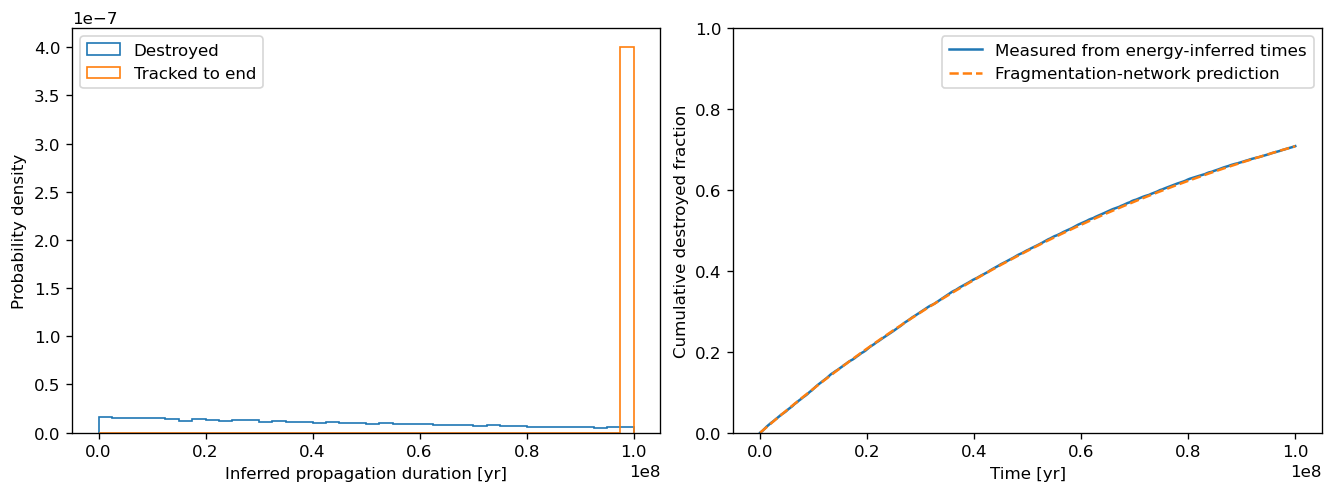

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
time_edges = np.linspace(0, t_end, 41)
for mask, label in [(destroyed, "Destroyed"), (tracked, "Tracked to end")]:
    axes[0].hist(elapsed_inferred[mask], bins=time_edges, histtype="step", density=True, label=label)
axes[0].set(xlabel="Inferred propagation duration [yr]", ylabel="Probability density")
axes[0].legend()

time_grid = np.linspace(0, t_end, 250)
predicted_destroyed = np.array([1 - (initial @ expm(Q * tt))[:k].sum() / n
                               for tt in time_grid])
measured_destroyed = np.array([np.count_nonzero(destroyed & (elapsed_inferred <= tt)) / n
                             for tt in time_grid])
axes[1].plot(time_grid, measured_destroyed, label="Measured from energy-inferred times")
axes[1].plot(time_grid, predicted_destroyed, "--", label="Fragmentation-network prediction")
axes[1].set(xlabel="Time [yr]", ylabel="Cumulative destroyed fraction", ylim=(0, 1))
axes[1].legend()
plt.show()


## Interpretation and saved information
Spectra show particle counts per logarithmic energy interval, not physical fluxes: injection uses a deterministic logarithmic grid with equal particle weights. B/C sums B10+B11 over C12+C13. There is no injected boron in this run; final carbon includes surviving primaries and fragmentation products. Cross sections and density are energy independent, so the predicted endpoint composition and B/C are energy independent; finite samples fluctuate.

Destroyed particles are transported through their final full timestep; tracked particles reach t_end. Individual durations are inferred from final energy using the assumed adiabatic law, not saved directly. Initial species IDs and initial positions are absent, so parent-to-daughter transitions and per-particle source-to-final displacement cannot be reconstructed. The transverse moment comparison includes expected source-disk contribution R²/2 and integrates the energy-dependent diffusion coefficient. Verify all parameters against the exact run that produced the binary.
